# Market regime model

In [89]:
from pathlib import Path
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from hmmlearn.hmm import GaussianHMM
from scipy.special import logsumexp

pd.set_option("display.max_columns", None)

features = [
    "daily_returns",
    "sign_persistence",
    "rolling_volatility",
    "trend",
]
seeds = [0, 1, 2, 3, 42]
state_counts = [3, 4, 5]


## Load the data

In [90]:
train_df = pd.read_csv("train_df.csv", index_col=0)
test_df = pd.read_csv("test_df.csv", index_col=0)
market = pd.read_csv("nifty_index.csv")

train_df = train_df[features].astype(float)
test_df = test_df[features].astype(float)

market["Date"] = pd.to_datetime(market["Date"])
market["Close"] = pd.to_numeric(market["Close"], errors="coerce")
market["daily_returns"] = market["Close"].pct_change()

if train_df.empty or test_df.empty:
    raise ValueError("Train or test data is empty.")
if train_df.isna().any().any() or test_df.isna().any().any():
    raise ValueError("Train/test features contain missing values.")
if not np.isfinite(train_df.to_numpy()).all() or not np.isfinite(test_df.to_numpy()).all():
    raise ValueError("Train/test features contain infinite values.")
if not train_df.index.is_monotonic_increasing or not test_df.index.is_monotonic_increasing:
    raise ValueError("Train/test indices must be in chronological order.")
if train_df.index.max() >= test_df.index.min():
    raise ValueError("Train and test indices overlap.")
if train_df.index.min() < 0 or test_df.index.max() >= len(market):
    raise ValueError("Feature indices do not match the market data rows.")
if market[["Date", "Close"]].isna().any().any():
    raise ValueError("Market data has missing dates or closing prices.")

print("Train:", train_df.shape)
print("Test:", test_df.shape)
print("Train rows:", train_df.index.min(), "to", train_df.index.max())
print("Test rows:", test_df.index.min(), "to", test_df.index.max())


Train: (3708, 4)
Test: (927, 4)
Train rows: 49 to 3756
Test rows: 3757 to 4683


## Try different numbers of states

In [91]:
results = []
models = {}
X_train = train_df.to_numpy()

for n in state_counts:
    for seed in seeds:
        hmm_model = GaussianHMM(
            n_components=n,
            covariance_type="full",
            n_iter=1000,
            random_state=seed,
        )
        hmm_model.fit(X_train)
        key = (n, seed)
        models[key] = hmm_model
        counts = np.bincount(hmm_model.predict(X_train), minlength=n)

        results.append({
            "states": n,
            "seed": seed,
            "converged": hmm_model.monitor_.converged,
            "iterations": hmm_model.monitor_.iter,
            "log_likelihood": hmm_model.score(X_train),
            "AIC": hmm_model.aic(X_train),
            "BIC": hmm_model.bic(X_train),
            "smallest_state_count": counts.min(),
        })

results_df = pd.DataFrame(results)
display(results_df.sort_values(["BIC", "AIC"]).reset_index(drop=True))


,states,seed,converged,iterations,log_likelihood,AIC,BIC,smallest_state_count
0,5,2,True,51,-12369.249336,24926.498673,25511.013978,257
1,5,0,True,89,-12417.480400,25022.960800,25607.476105,306
2,5,1,True,29,-12461.883262,25111.766525,25696.281830,160
3,5,42,True,262,-12479.413203,25146.826407,25731.341712,254
4,4,3,True,164,-13018.227334,26178.454668,26619.950271,394
5,4,0,True,42,-13268.793410,26679.586821,27121.082424,315
6,4,2,True,38,-13289.214424,26720.428848,27161.924451,184
7,5,3,True,45,-13259.251446,26706.502891,27291.018196,314
8,4,42,True,30,-13465.053885,27072.107769,27513.603372,394
9,4,1,True,49,-13530.439718,27202.879436,27644.375039,429


## Pick the model

In [92]:
valid = results_df[results_df["converged"]].copy()
if valid.empty:
    raise RuntimeError("None of the candidate models converged.")

best = valid.sort_values(["BIC", "AIC"]).iloc[0]
best_key = (int(best["states"]), int(best["seed"]))
model = models[best_key]

print("States:", best_key[0])
print("Seed:", best_key[1])
print("Converged:", model.monitor_.converged)
print("Training log-likelihood:", model.score(X_train))
print("BIC:", model.bic(X_train))


States: 5
Seed: 2
Converged: True
Training log-likelihood: -12369.249336266623
BIC: 25511.013977641705


## Look at the training regimes

Rows in each state:


,count
state,
0,1023
1,1011
2,554
3,863
4,257


Average feature values by state:


,daily_returns,sign_persistence,rolling_volatility,trend
state,,,,
0,-0.017,-0.010,-0.067,0.135
1,0.032,-0.031,-0.739,0.368
2,0.022,0.060,0.861,0.254
3,-0.025,0.191,-0.376,-0.170
4,-0.021,-0.606,2.581,-1.960


,State 0,State 1,State 2,State 3,State 4
State 0,0.965,0.003,0.011,0.021,0.000
State 1,0.001,0.979,0.000,0.020,0.000
State 2,0.025,0.000,0.961,0.000,0.013
State 3,0.023,0.020,0.003,0.954,0.000
State 4,0.000,0.000,0.030,0.000,0.970


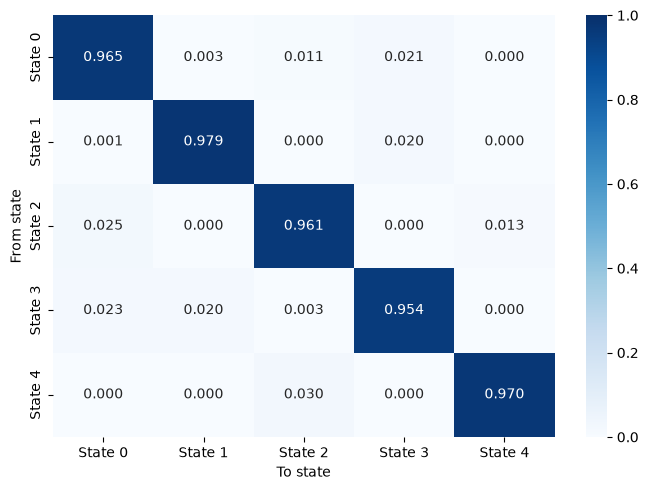

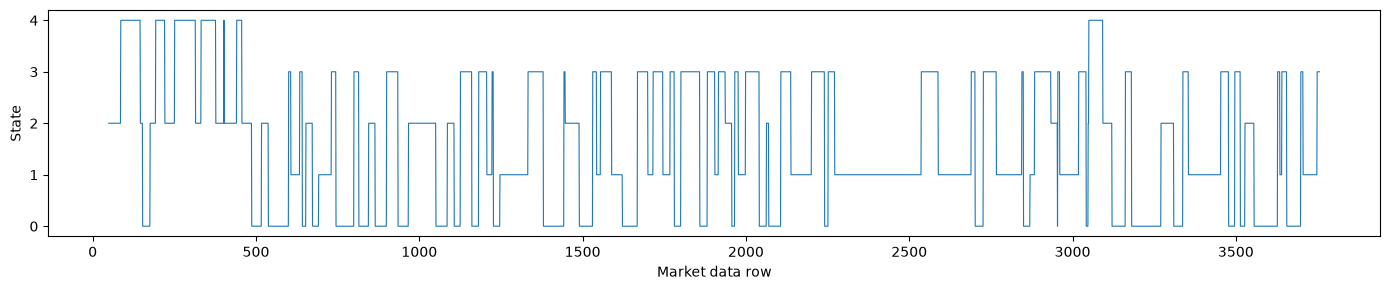

In [93]:
train_states = model.predict(X_train)
train_check = train_df.copy()
train_check["state"] = train_states

print("Rows in each state:")
display(train_check["state"].value_counts().sort_index().rename("count").to_frame())

print("Average feature values by state:")
display(train_check.groupby("state")[features].mean().round(3))

transition_df = pd.DataFrame(
    model.transmat_,
    index=[f"State {i}" for i in range(model.n_components)],
    columns=[f"State {i}" for i in range(model.n_components)],
)
display(transition_df.round(3))

plt.figure(figsize=(7, 5))
sns.heatmap(transition_df, annot=True, fmt=".3f", vmin=0, vmax=1, cmap="Blues")
plt.xlabel("To state")
plt.ylabel("From state")
plt.tight_layout()
plt.show()

plt.figure(figsize=(14, 3))
plt.plot(train_df.index, train_states, linewidth=0.8)
plt.xlabel("Market data row")
plt.ylabel("State")
plt.tight_layout()
plt.show()


## Filter the test data

In [94]:
def normalize_log_probs(values):
    total = logsumexp(values)
    if not np.isfinite(total):
        raise FloatingPointError("Could not normalize state probabilities.")
    return np.exp(values - total)


def filter_states(hmm_model, X, previous_probs=None):
    X = np.asarray(X, dtype=float)
    if X.ndim != 2:
        raise ValueError("X must be a 2D array.")
    if len(X) == 0:
        return np.empty((0, hmm_model.n_components))

    log_emissions = hmm_model._compute_log_likelihood(X)
    log_transition = np.log(np.clip(hmm_model.transmat_, 1e-300, 1.0))
    probs = np.zeros((len(X), hmm_model.n_components))

    if previous_probs is None:
        previous = hmm_model.startprob_.copy()
        first_row = True
    else:
        previous = np.asarray(previous_probs, dtype=float)
        if previous.shape != (hmm_model.n_components,) or previous.sum() <= 0:
            raise ValueError("Previous probabilities have the wrong shape or sum.")
        previous = previous / previous.sum()
        first_row = False

    for i, emission in enumerate(log_emissions):
        if i == 0 and first_row:
            log_prior = np.log(np.clip(previous, 1e-300, 1.0))
        else:
            log_prior = logsumexp(
                np.log(np.clip(previous, 1e-300, 1.0))[:, None] + log_transition,
                axis=0,
            )

        current = normalize_log_probs(log_prior + emission)
        probs[i] = current
        previous = current

    return probs


train_filtered = filter_states(model, X_train)

# Pass the last training probability into the test filter.
# The filter applies the transition once before the first test row.
test_filtered = filter_states(
    model,
    test_df.to_numpy(),
    previous_probs=train_filtered[-1],
)

prob_cols = [f"State {i}" for i in range(model.n_components)]
test_probs = pd.DataFrame(test_filtered, index=test_df.index, columns=prob_cols)
test_probs["state"] = test_filtered.argmax(axis=1)

print("Probability sums:", test_filtered.sum(axis=1).min(), "to", test_filtered.sum(axis=1).max())
print("Test state counts:")
display(test_probs["state"].value_counts().sort_index().rename("count").to_frame())
display(test_probs.head())


Probability sums: 0.9999999999999992 to 1.0000000000000009
Test state counts:


,count
state,
0,59
1,535
2,50
3,283


,State 0,State 1,State 2,State 3,State 4,state
3757,1.196375e-06,0.000940,0.000059,0.999000,8.641541e-10,3
3758,3.352366e-06,0.000472,0.000065,0.999459,1.044875e-09,3
3759,1.883022e-06,0.000772,0.000063,0.999163,1.084341e-09,3
3760,1.076209e-06,0.000494,0.000033,0.999472,1.754994e-09,3
3761,5.313279e-08,0.012086,0.000187,0.987727,5.401789e-09,3


## Match states with next-day returns

State counts:


,count
state,
0,59
1,535
2,50
3,282


Next-day returns by state:


,count,mean,std,min,max
state,,,,,
0,59,0.00240,0.01145,-0.02604,0.03818
1,535,0.00043,0.00669,-0.02679,0.03254
2,50,0.00351,0.00941,-0.01138,0.03778
3,282,-0.00100,0.00889,-0.05929,0.02387


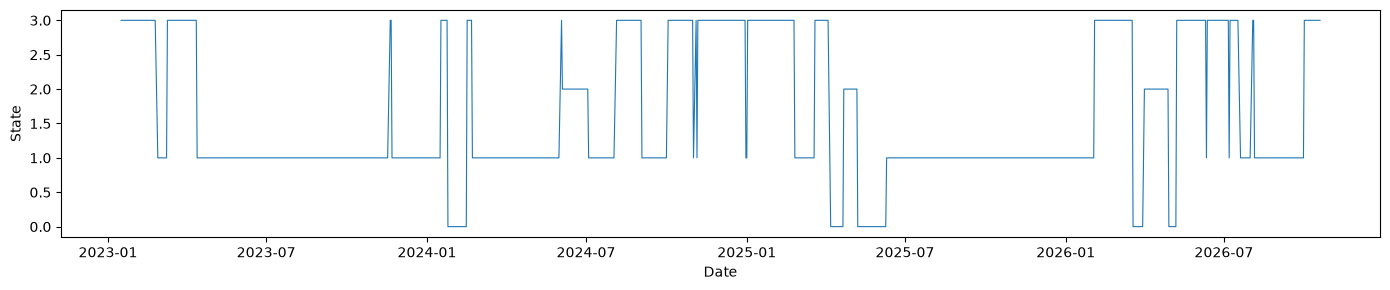

In [95]:
market_by_row = market.reset_index(drop=True)
test_eval = test_probs.copy()
row_numbers = test_eval.index.to_numpy(dtype=int)

test_eval["date"] = market_by_row.loc[row_numbers, "Date"].to_numpy()
test_eval["close"] = market_by_row.loc[row_numbers, "Close"].to_numpy()
next_returns = market_by_row["daily_returns"].shift(-1)
test_eval["next_day_return"] = next_returns.loc[row_numbers].to_numpy()
test_eval = test_eval.dropna(subset=["next_day_return"])

print("State counts:")
display(test_eval["state"].value_counts().sort_index().rename("count").to_frame())

print("Next-day returns by state:")
display(
    test_eval.groupby("state")["next_day_return"]
    .agg(["count", "mean", "std", "min", "max"])
    .round(5)
)

plt.figure(figsize=(14, 3))
plt.plot(test_eval["date"], test_eval["state"], linewidth=0.8)
plt.xlabel("Date")
plt.ylabel("State")
plt.tight_layout()
plt.show()


## Save the results

In [96]:
joblib.dump(model, "hmm_model.joblib")
test_eval.to_csv("causal_test_regimes.csv", index_label="market_row")
print("Saved hmm_model.joblib and causal_test_regimes.csv")


Saved hmm_model.joblib and causal_test_regimes.csv
